In [1]:
import sys
sys.path.insert(0, ".")
sys.path.insert(0, "../scripts")   # graficos/scripts/paleta.py

import numpy as np
import matplotlib.pyplot as plt
from paleta import cmap_sequencial
from matplotlib.colors import LinearSegmentedColormap, PowerNorm
from dados_atividades import load_study_activities, load_study_stages, STAGE_NAMES, STAGE_ORDER

# rampa da paleta compartilhada (graphic/paleta.py), de #eef5f6 até #002c35
cmap = cmap_sequencial("activities_cmap", com_branco=False)

In [2]:
# estudos que passam por cada par de estágios, contados em ../data/tabela_de_codigos.csv (dados_atividades.py)
from dados_atividades import COOCORRENCIA_ESTAGIOS as COOCORRENCIA

n = len(STAGE_ORDER)
matriz = np.zeros((n, n), dtype=int)
for i, si in enumerate(STAGE_ORDER):
    for j, sj in enumerate(STAGE_ORDER):
        matriz[i, j] = COOCORRENCIA[(si, sj)]

labels = [f"T{s}\n{STAGE_NAMES[s]}" for s in STAGE_ORDER]

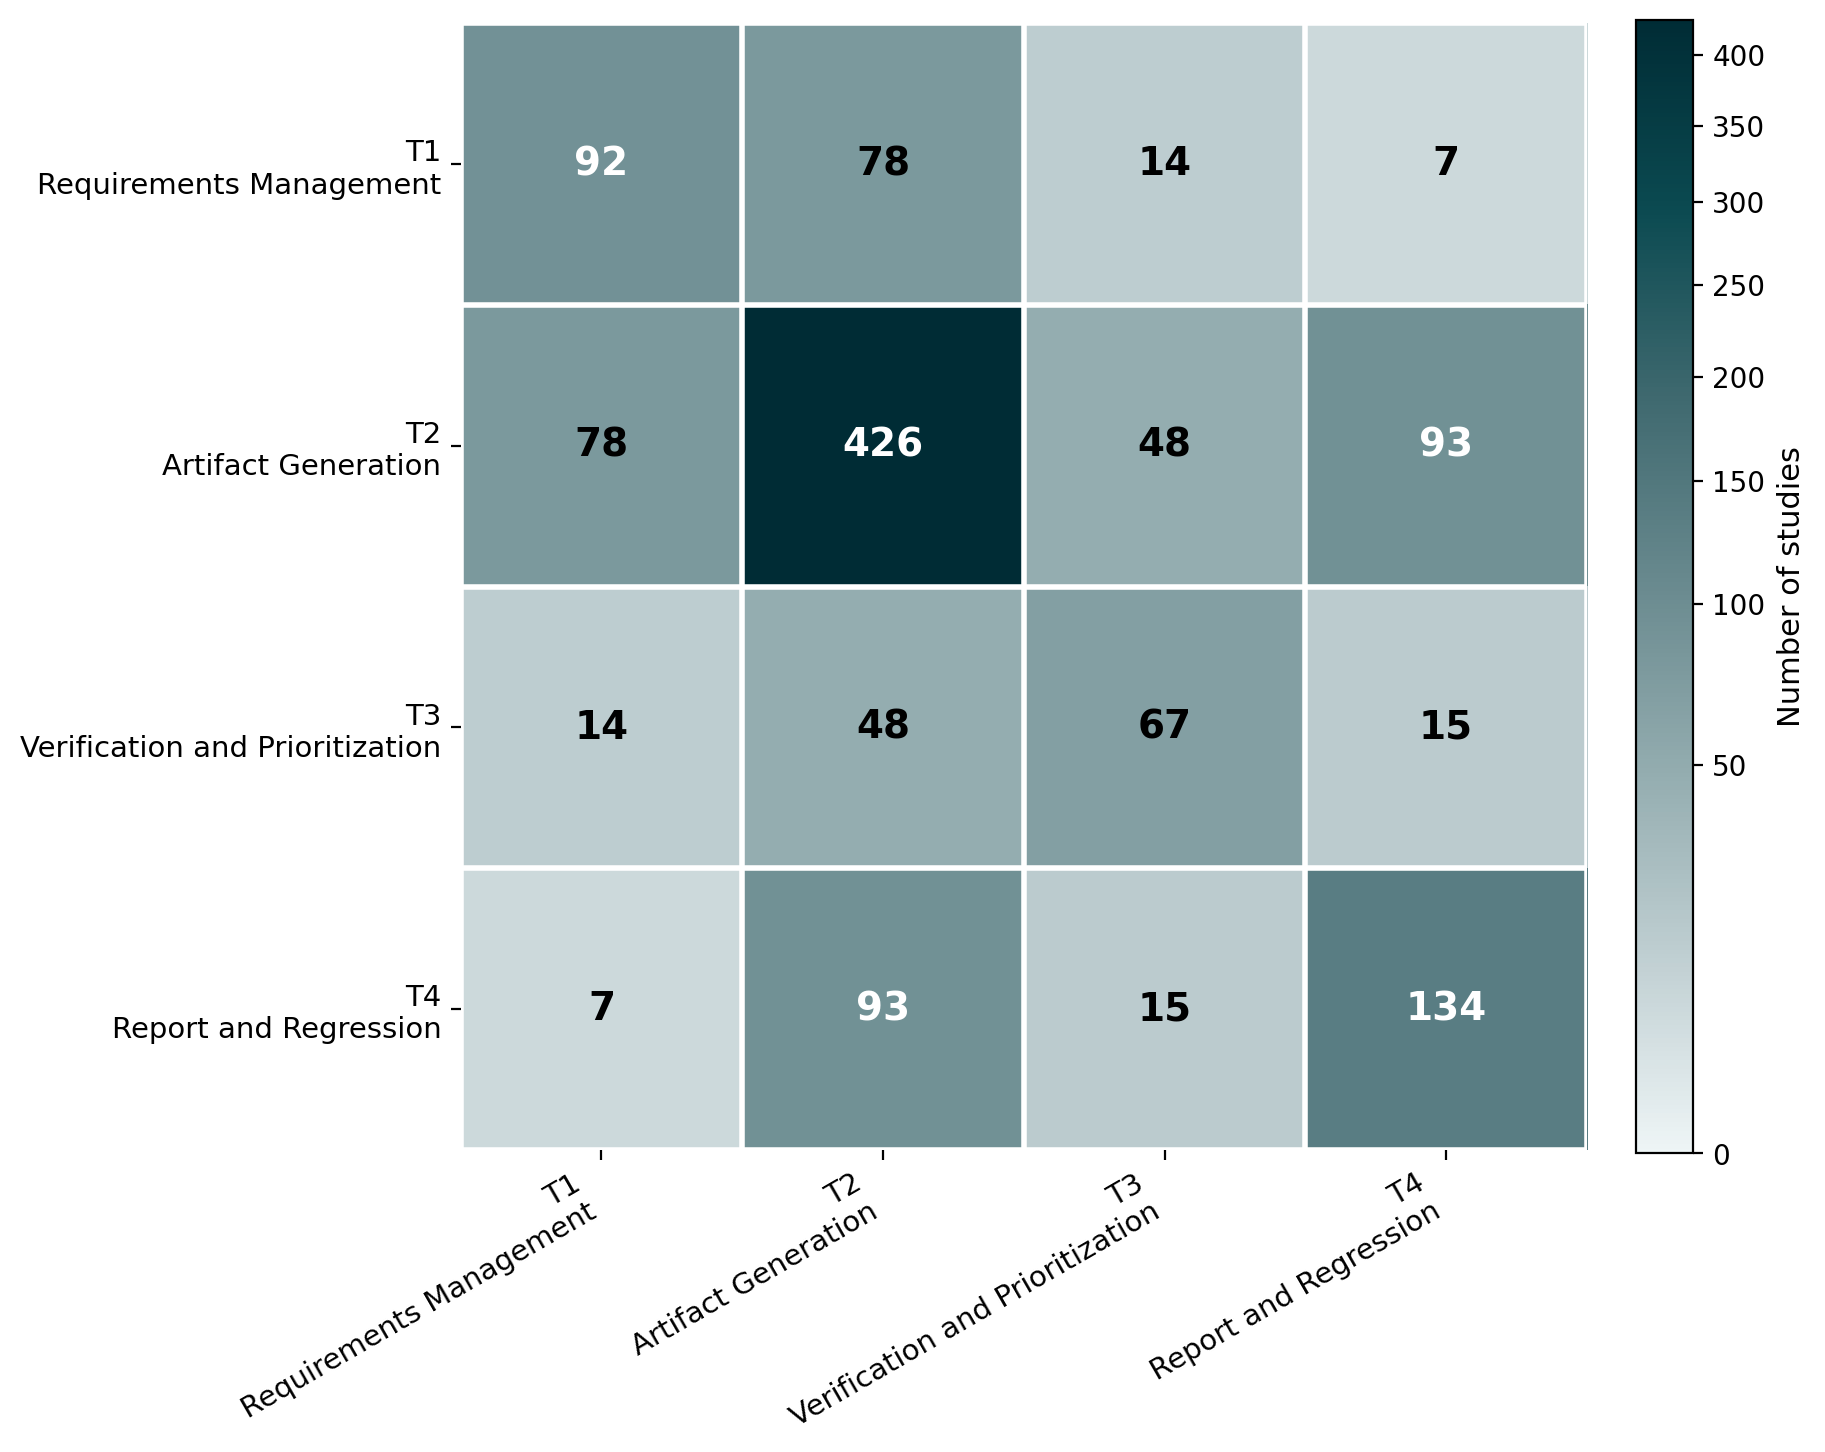

In [3]:
fig, ax = plt.subplots(figsize=(9, 8), dpi=200)

# escala em raiz quadrada: sem ela o 426 da diagonal deixa quase todas as células claras
im = ax.imshow(matriz, cmap=cmap, norm=PowerNorm(gamma=0.5, vmin=0, vmax=matriz.max()))

ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=10.5)
ax.set_yticklabels(labels, fontsize=10.5)

for i in range(n):
    for j in range(n):
        v = matriz[i, j]
        cor_fundo = im.cmap(im.norm(v))
        luminancia = 0.299 * cor_fundo[0] + 0.587 * cor_fundo[1] + 0.114 * cor_fundo[2]
        cor_texto = "black" if luminancia > 0.55 else "white"
        if v == 0 and i != j:
            ax.text(j, i, "×", ha="center", va="center", fontsize=22, fontweight="bold", color="#c0392b")
        else:
            ax.text(j, i, str(v), ha="center", va="center", fontsize=14, fontweight="bold", color=cor_texto)

# Bordas finas entre células
ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Number of studies", fontsize=11)

plt.tight_layout()
plt.savefig("heatmap_estagios.png", bbox_inches="tight", dpi=200)
plt.show()